# Regional Dependence of Power Grid Resilience

This notebook investigates how the **resilience of a high-voltage (HV) power grid** varies across a full year of operation, using [SimBench](https://simbench.de/en/) benchmark grids and [pandapower](https://www.pandapower.org/) for AC power flow simulation.

**Workflow:**
1. Load a SimBench HV grid and its yearly load/generation profiles.
2. Run a power flow for every snapshot in the period and extract resilience-relevant results (line loading, voltages, worst-case components).
3. Identify the grid's **System Reserve** (the least-used lines/buses) and **System Burden** (the most heavily-loaded lines/buses) across the whole period.
4. Analyse the grid's topology using graph theory (betweenness, closeness, eigenvector centrality) to identify structurally critical buses.


## 1. Setup
Import the packages needed for grid modelling, power flow, plotting and graph analysis.

In [1]:
# Import all the Functions required
from Functions import *

## 2. Load the SimBench Grid
Download/load a SimBench benchmark grid by its code and visualise its topology.

This pandapower network includes the following parameter tables:
   - bus (235 elements)
   - load (218 elements)
   - sgen (235 elements)
   - storage (114 elements)
   - switch (11 elements)
   - ext_grid (1 element)
   - line (278 elements)
   - trafo (5 elements)
   - measurement (66 elements)
   - substation (15 elements)
   - loadcases (6 elements)


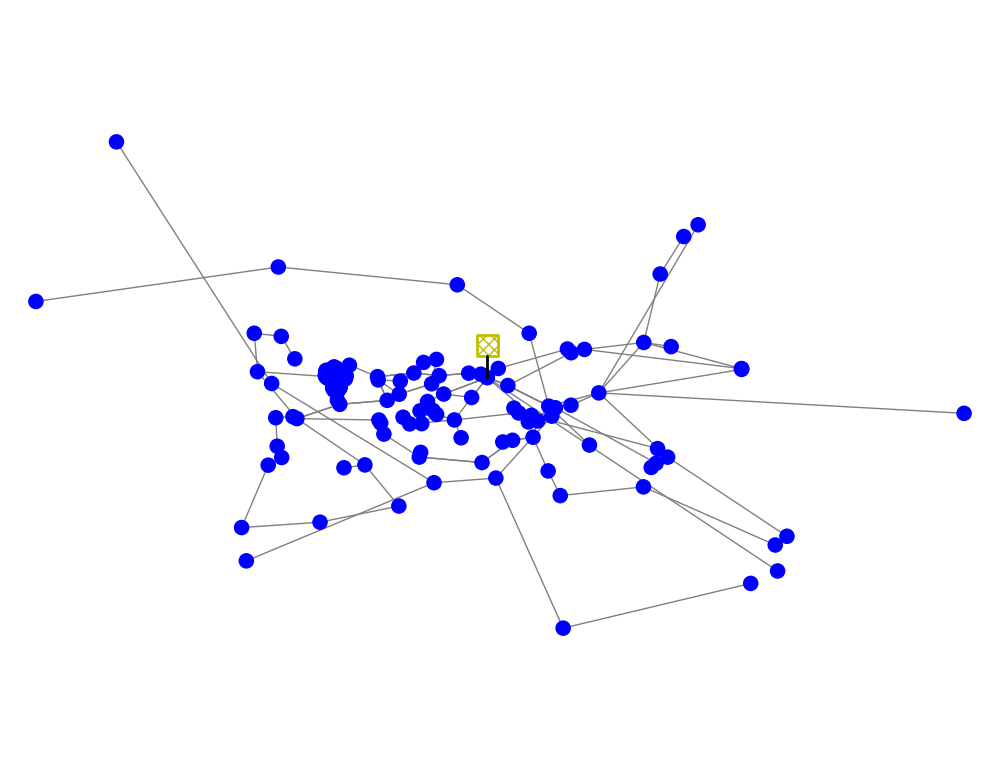

In [2]:
# SimBench grid code to analyse - see sb.collect_all_simbench_codes() for all available options
network = "1-HVMV-urban-3.201-1-no_sw" # "1-HVMV-urban-3.201-1-no_sw" and "1-HV-urban--0-no_sw"
id = 2

net_simbench = import_sb_grid(network)

## 3. Load and Generation Profiles
Extract the full-year time series of load and generation for the grid, and plot the total system profile at a chosen resolution.

Available profile keys:
  ('load', 'p_mw')                    shape=(35136, 218)
  ('load', 'q_mvar')                  shape=(35136, 218)
  ('sgen', 'p_mw')                    shape=(35136, 235)
  ('gen', 'p_mw')                     shape=(35136, 0)
  ('storage', 'p_mw')                 shape=(35136, 114)


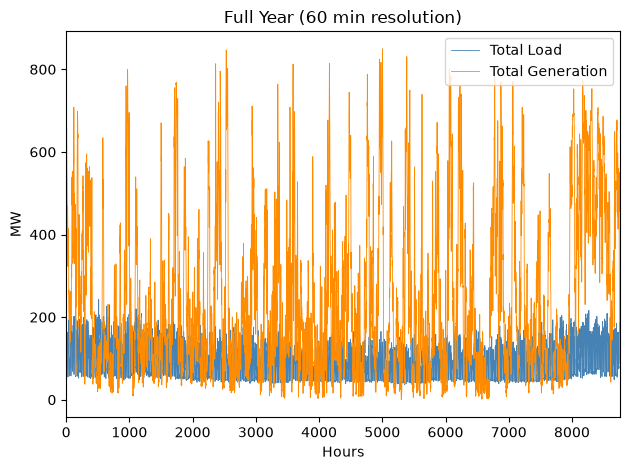

In [3]:
profiles = get_profiles(net_simbench, 4, id)

## 4. Time-Series Power Flow Simulation

For every snapshot in the profile period, the grid's loads/generation are updated and an AC power flow is solved. From each converged snapshot we extract:

- **Summary results** (worst line, worst bus, voltage limits) -> `snapshot_df`, used for the overview plot below.
- **Full per-line and per-bus loading history** -> `line_loading_history` / `bus_power_history`, used in Section 4.1 to find the System Reserve and System Burden.

  Progress: 0/8750 (t=0)
  Progress: 50/8750 (t=200)
  Progress: 100/8750 (t=400)
  Progress: 150/8750 (t=600)
  Progress: 200/8750 (t=800)
  Progress: 250/8750 (t=1000)
  Progress: 300/8750 (t=1200)
  Progress: 350/8750 (t=1400)
  Progress: 400/8750 (t=1600)
  Progress: 450/8750 (t=1800)
  Progress: 500/8750 (t=2000)
  Progress: 550/8750 (t=2200)
  Progress: 600/8750 (t=2400)
  Progress: 650/8750 (t=2600)
  Progress: 700/8750 (t=2800)
  Progress: 750/8750 (t=3000)
  Progress: 800/8750 (t=3200)
  Progress: 850/8750 (t=3400)
  Progress: 900/8750 (t=3600)
  Progress: 950/8750 (t=3800)
  Progress: 1000/8750 (t=4000)
  Progress: 1050/8750 (t=4200)
  Progress: 1100/8750 (t=4400)
  Progress: 1150/8750 (t=4600)
  Progress: 1200/8750 (t=4800)
  Progress: 1250/8750 (t=5000)
  Progress: 1300/8750 (t=5200)
  Progress: 1350/8750 (t=5400)
  Progress: 1400/8750 (t=5600)
  Progress: 1450/8750 (t=5800)
  Progress: 1500/8750 (t=6000)
  Progress: 1550/8750 (t=6200)
  Progress: 1600/8750 (t=6400)
  Progr

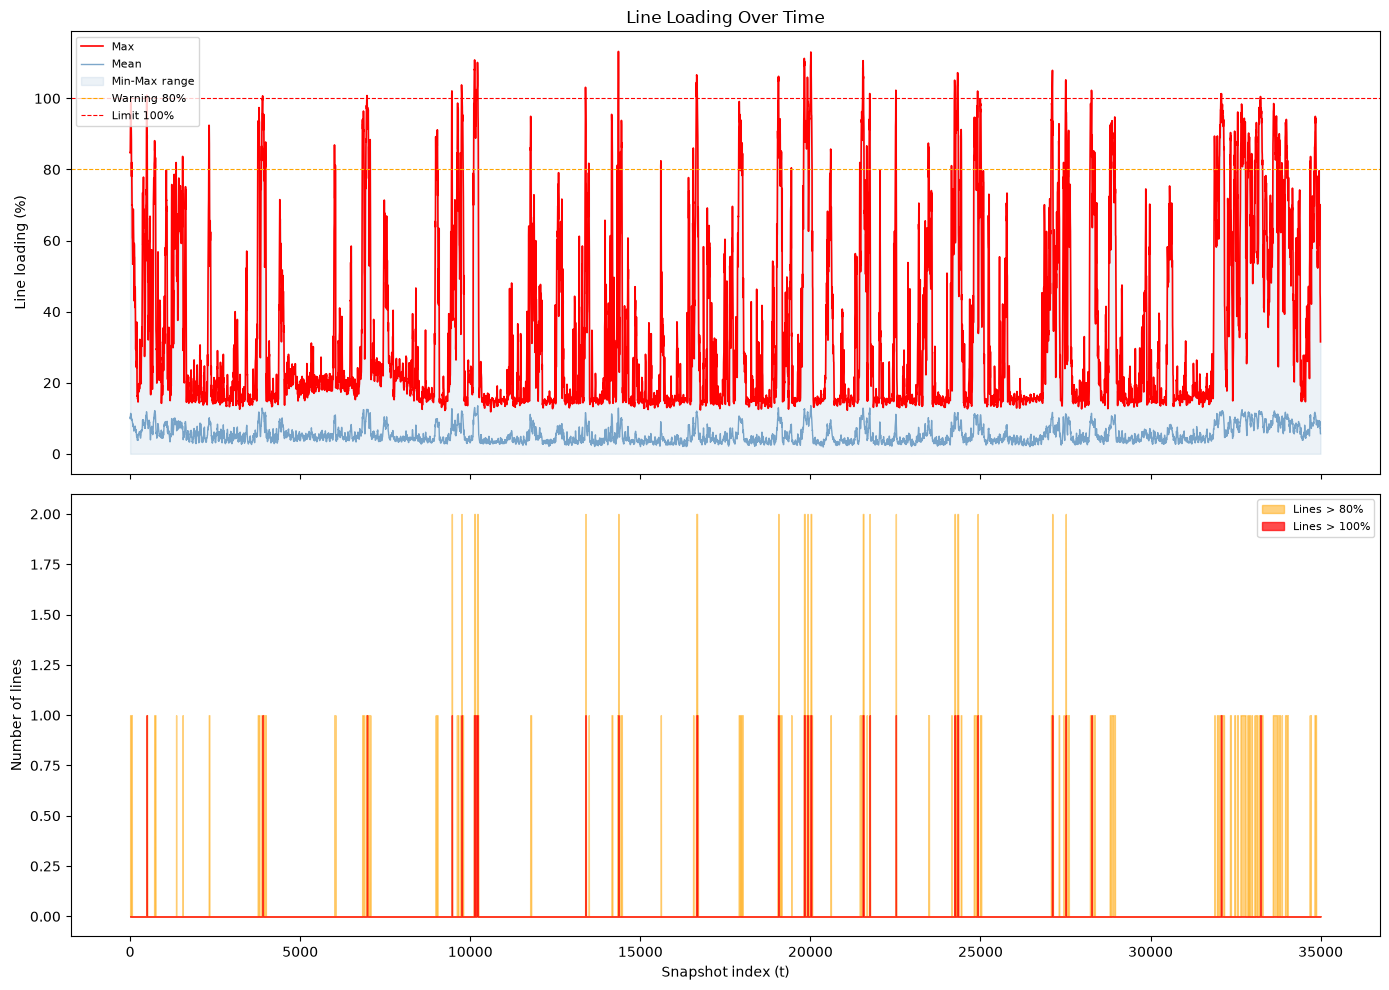

In [4]:
snapshot_df, line_loading_history, bus_power_history, bus_voltage_history = run_powerflow_over_period(net_simbench, profiles, id, 0, 35000, 4)
plot_line_loading_over_time(snapshot_df, id)

### 4.1 System Reserve and System Burden

These two indicators identify **which specific lines and buses** are under-used or over-used across the whole simulated period, using the full `line_loading_history` / `bus_power_history` collected above:

- **System Reserve** - the lines/buses that are **least used** across the whole period. They represent spare capacity in the grid: components that are rarely stressed and could take on more load if the network were reconfigured or reinforced elsewhere.
- **System Burden** - the lines/buses that are **highly loaded at times** across the period. They are the recurring bottlenecks - the components that should be reinforced/upgraded over time to keep the network healthy as demand grows.

In [5]:
reserve_lines, reserve_buses = find_system_reserve(line_loading_history, bus_voltage_history, net_simbench, top_n=10)
burden_lines, burden_buses = find_system_burden(line_loading_history, bus_voltage_history, net_simbench, top_n=10, v_band=(0.90, 1.10))

Top 10 most UNDER-USED lines (System Reserve):
  HV2 Line 117 (idx 116): mean loading = 0.04%  |  connects bus 87 <-> bus 375
  MV3.201 loop_line 3 (idx 266): mean loading = 0.05%  |  connects bus 476 <-> bus 504
  MV3.201 loop_line 10 (idx 273): mean loading = 0.06%  |  connects bus 485 <-> bus 510
  MV3.201 loop_line 11 (idx 274): mean loading = 0.07%  |  connects bus 467 <-> bus 475
  MV3.201 loop_line 8 (idx 271): mean loading = 0.07%  |  connects bus 436 <-> bus 440
  MV3.201 loop_line 6 (idx 269): mean loading = 0.07%  |  connects bus 529 <-> bus 535
  MV3.201 loop_line 7 (idx 270): mean loading = 0.08%  |  connects bus 421 <-> bus 514
  HV2 Line 119 (idx 118): mean loading = 0.10%  |  connects bus 165 <-> bus 377
  MV3.201 loop_line 4 (idx 267): mean loading = 0.11%  |  connects bus 493 <-> bus 518
  MV3.201 loop_line 5 (idx 268): mean loading = 0.12%  |  connects bus 524 <-> bus 543

Top 10 most STABLE buses (System Reserve, by voltage):
  EHV Bus 1865 (idx 0): mean |vm - 1.0| 

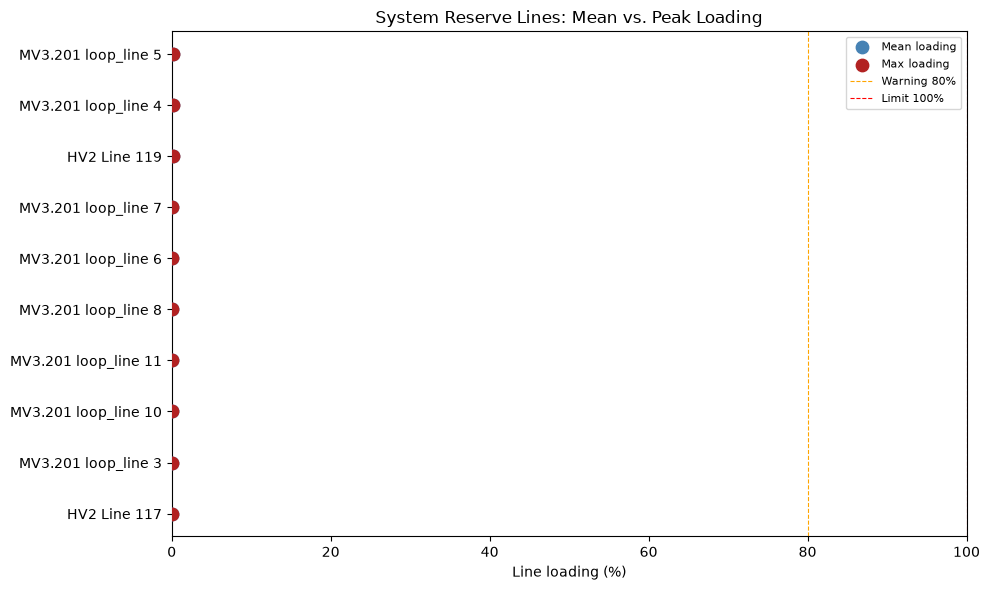

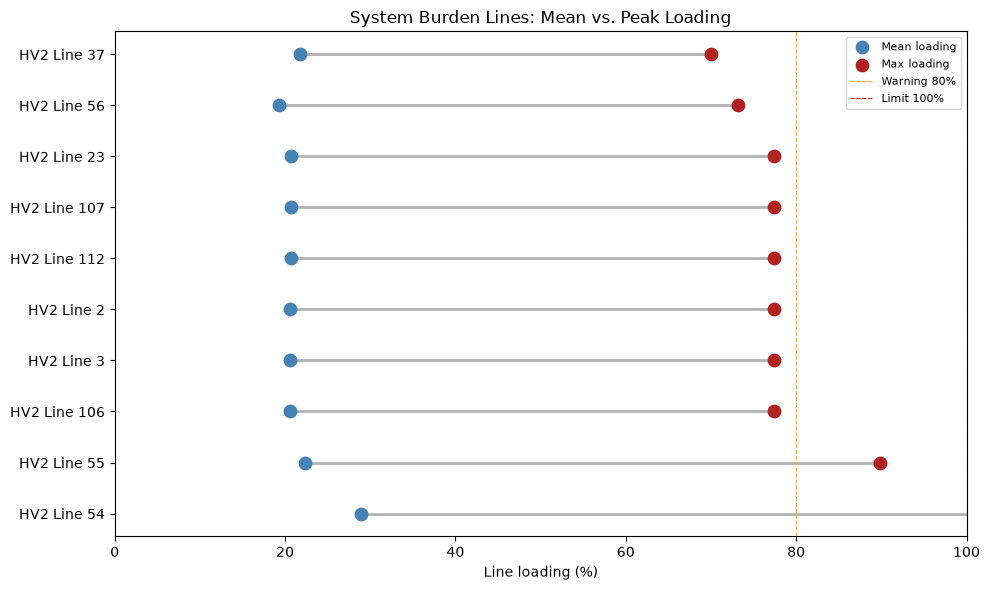

In [6]:
plot_mean_vs_max(reserve_lines.index, line_loading_history, net_simbench,
                  "System Reserve Lines: Mean vs. Peak Loading", "reserve_mean_vs_max", id)

plot_mean_vs_max(burden_lines.index, line_loading_history, net_simbench,
                  "System Burden Lines: Mean vs. Peak Loading", "burden_mean_vs_max", id)

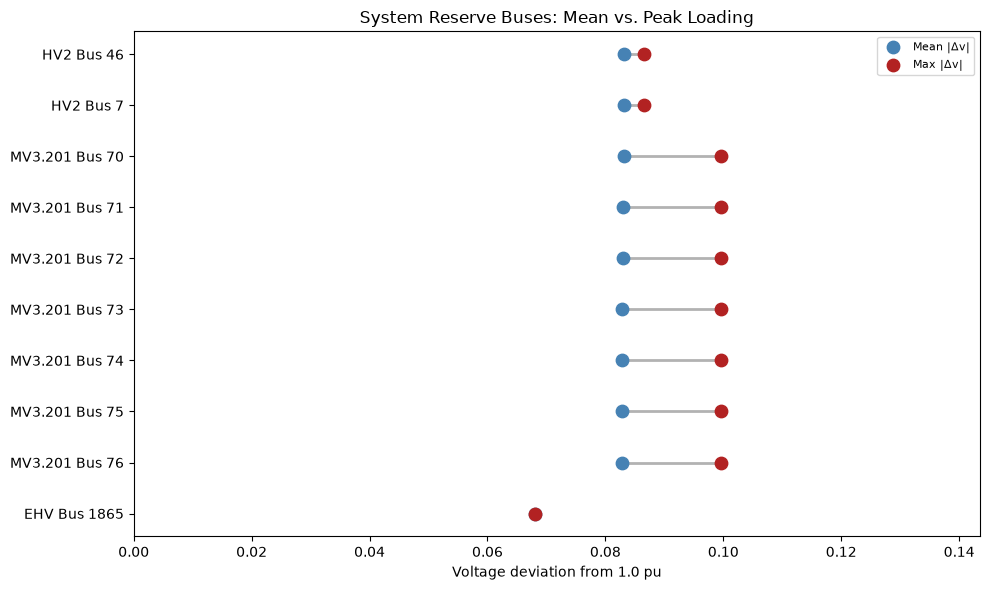

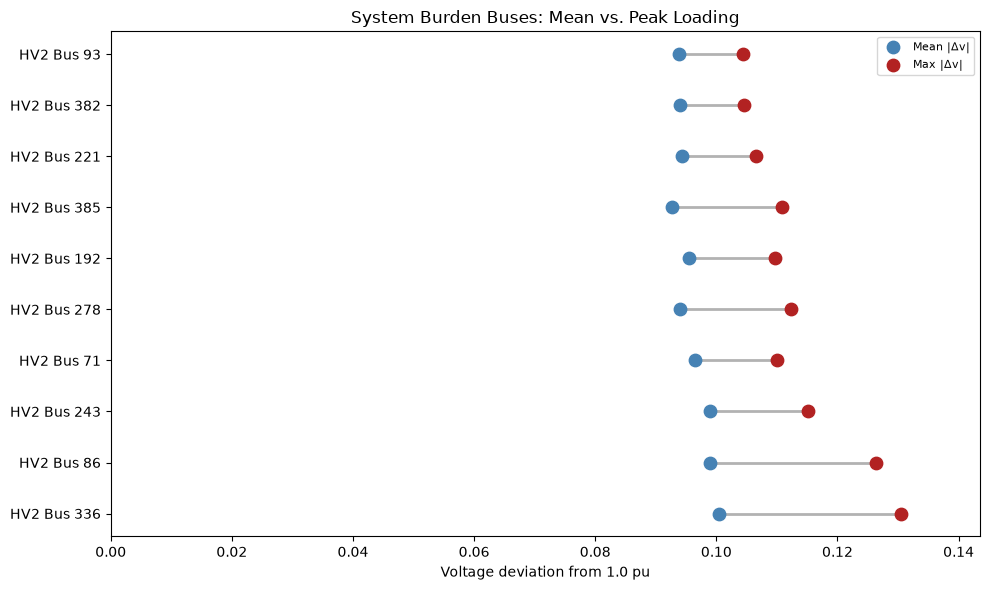

In [7]:
all_ids = list(reserve_buses.index) + list(burden_buses.index)
combined_dev = (bus_voltage_history[all_ids] - 1.0).abs()
x_max = combined_dev.values.max() * 1.1  # small padding so the rightmost dot isn't clipped

plot_voltage_deviation_mean_vs_max(reserve_buses.index, bus_voltage_history, net_simbench,
                                    "System Reserve Buses: Mean vs. Peak Loading", "reserve_mean_vs_max_buses", id,
                                    xlim=(0, x_max))

plot_voltage_deviation_mean_vs_max(burden_buses.index, bus_voltage_history, net_simbench,
                                    "System Burden Buses: Mean vs. Peak Loading", "burden_mean_vs_max_buses", id,
                                    xlim=(0, x_max))

## 5. Network Topology and Graph Construction

Beyond power flow, the grid's *topology* also determines resilience: some buses are structurally more critical than others regardless of loading. We extract the bus/line topology into a graph representation for this analysis.

In [8]:
nodes = get_node_list(net_simbench)
arcs = get_arc_list(net_simbench)

In [9]:
graph_simbench, layout = make_graph_net(nodes, arcs, id)

## 6. Centrality Analysis

Three classic centrality measures highlight structurally important buses:

- **Betweenness** - how often a bus lies on the shortest path between other buses (bridge/bottleneck role).
- **Closeness** - how quickly a bus can reach all other buses (average distance).
- **Eigenvector** - how well-connected a bus is to other well-connected buses (influence).

     NodeIndex        x        y  betweenness
0            0  9.82158  52.4249         0.00
5            5  9.74204  52.3670       160.17
11          11  9.82158  52.4249      2308.68
27          27  9.91718  52.2782       285.00
31          31  9.81336  52.2914       507.98
..         ...      ...      ...          ...
539        539  9.59366  52.4296       381.00
540        540  9.59426  52.4298       261.00
541        541  9.59686  52.4299       141.00
542        542  9.59746  52.4298        21.00
543        543  9.59966  52.4285        21.00

[235 rows x 4 columns]


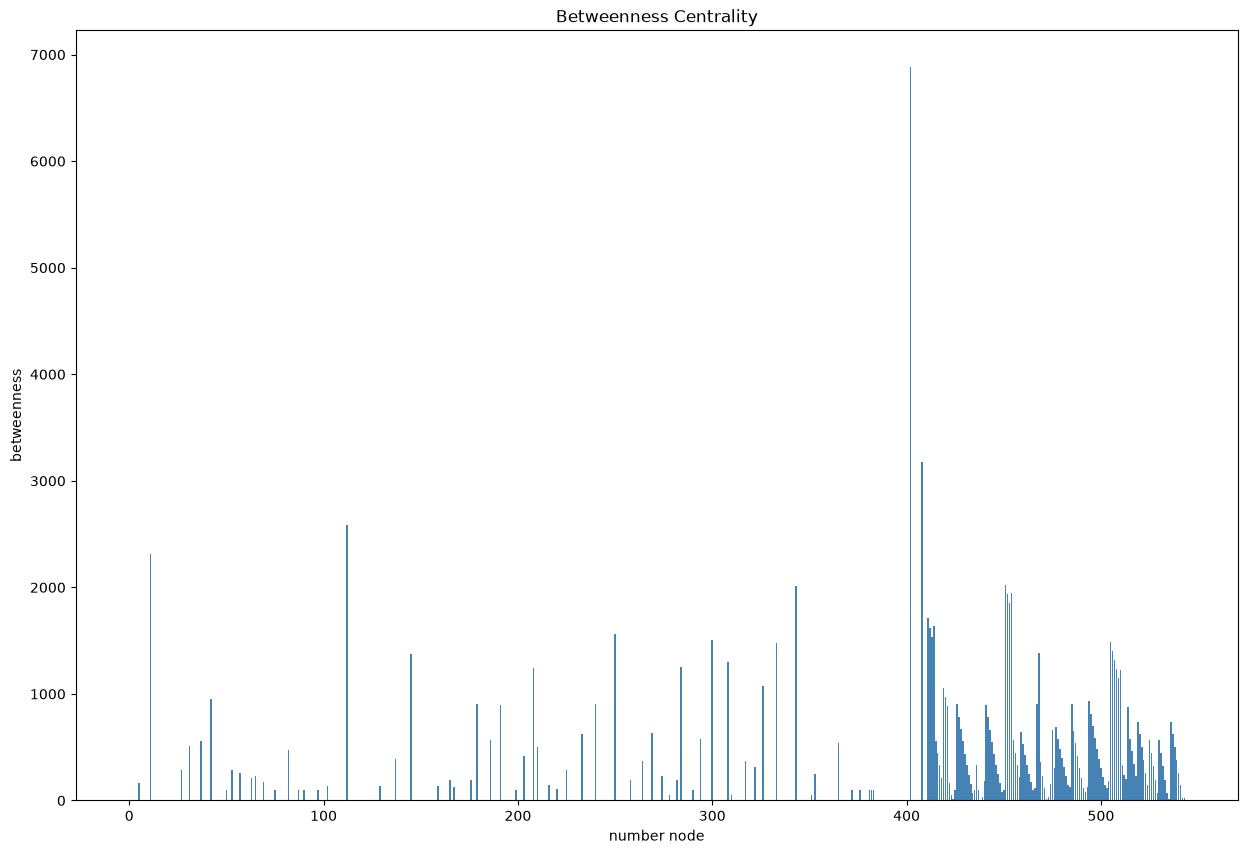

In [10]:
calculate_betweenness_centrality(graph_simbench, nodes, id)

     NodeIndex        x        y  betweenness  closeness
0            0  9.82158  52.4249         0.00        NaN
5            5  9.74204  52.3670       160.17       0.13
11          11  9.82158  52.4249      2308.68       0.19
27          27  9.91718  52.2782       285.00       0.14
31          31  9.81336  52.2914       507.98       0.14
..         ...      ...      ...          ...        ...
539        539  9.59366  52.4296       381.00       0.10
540        540  9.59426  52.4298       261.00       0.10
541        541  9.59686  52.4299       141.00       0.09
542        542  9.59746  52.4298        21.00       0.08
543        543  9.59966  52.4285        21.00       0.08

[235 rows x 5 columns]


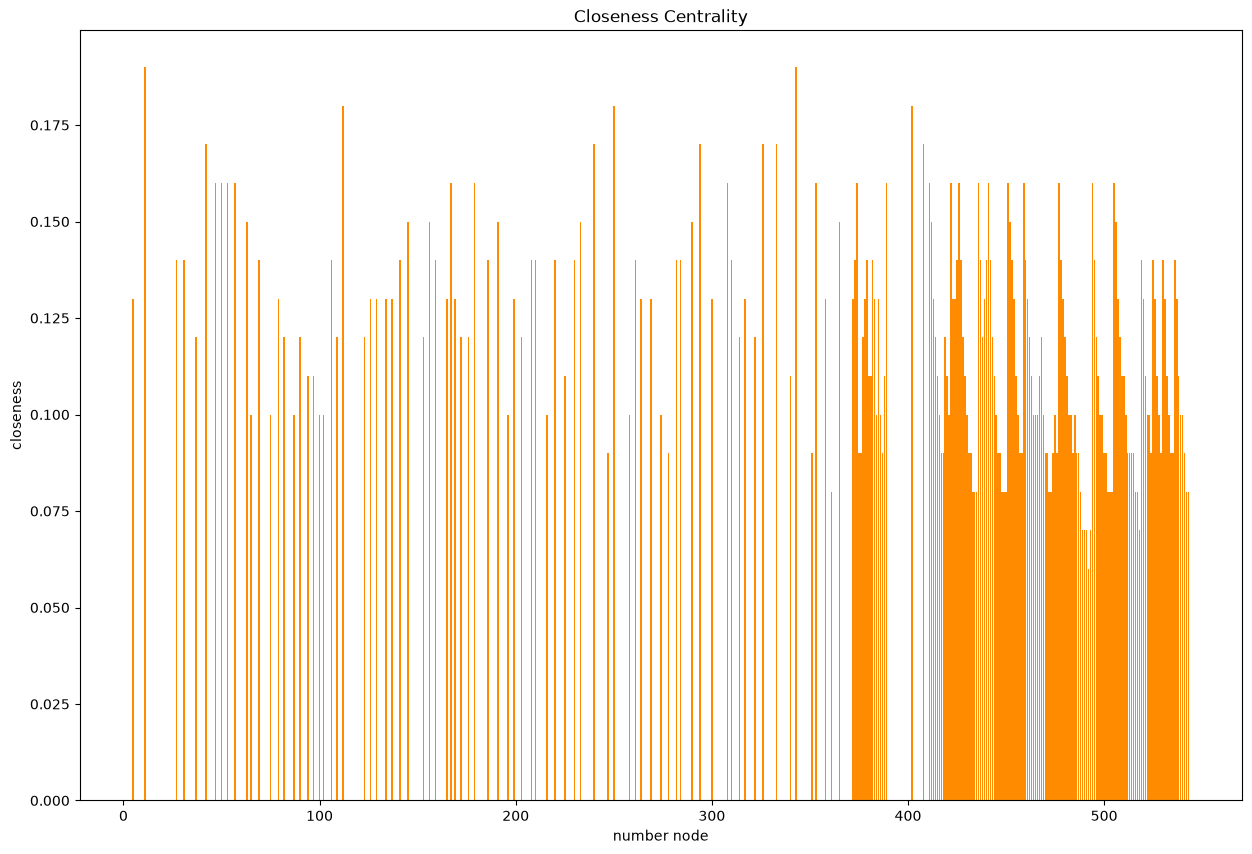

In [11]:
calculate_closeness_centrality(graph_simbench, nodes, id)

In [12]:
# Which buses are centrality "hubs"?
top_betweenness = nodes.set_index('NodeIndex')['betweenness'].nlargest(10).index
top_closeness = nodes.set_index('NodeIndex')['closeness'].nlargest(10).index

print("Top betweenness buses:", list(top_betweenness))
print("Top closeness buses:", list(top_closeness))

Top betweenness buses: [402, 408, 112, 11, 451, 343, 454, 452, 453, 411]
Top closeness buses: [11, 343, 112, 250, 402, 42, 240, 294, 326, 333]


In [13]:
table = build_betweenness_loading_table(burden_lines, nodes, net_simbench, top_n_betweenness=10)
print(table.to_string(index=False))

n_connected = (table['Connects to Top-Betweenness Bus?'] == 'Yes').sum()
print(f"\n{n_connected} of {len(table)} highest-loaded lines connect directly to a top-betweenness bus.")

        Line  Peak Loading (%)  From Bus  From Bus Betweenness  To Bus  To Bus Betweenness Connects to Top-Betweenness Bus?
 HV2 Line 54            113.20        53                285.00     112             2589.71                              Yes
 HV2 Line 55             89.79        53                285.00     282              192.00                               No
HV2 Line 106             77.40       112               2589.71     343             2017.01                              Yes
  HV2 Line 3             77.40       112               2589.71     343             2017.01                              Yes
  HV2 Line 2             77.40       112               2589.71     343             2017.01                              Yes
HV2 Line 112             77.37        11               2308.68     343             2017.01                              Yes
HV2 Line 107             77.37        11               2308.68     343             2017.01                              Yes
 HV2 Lin

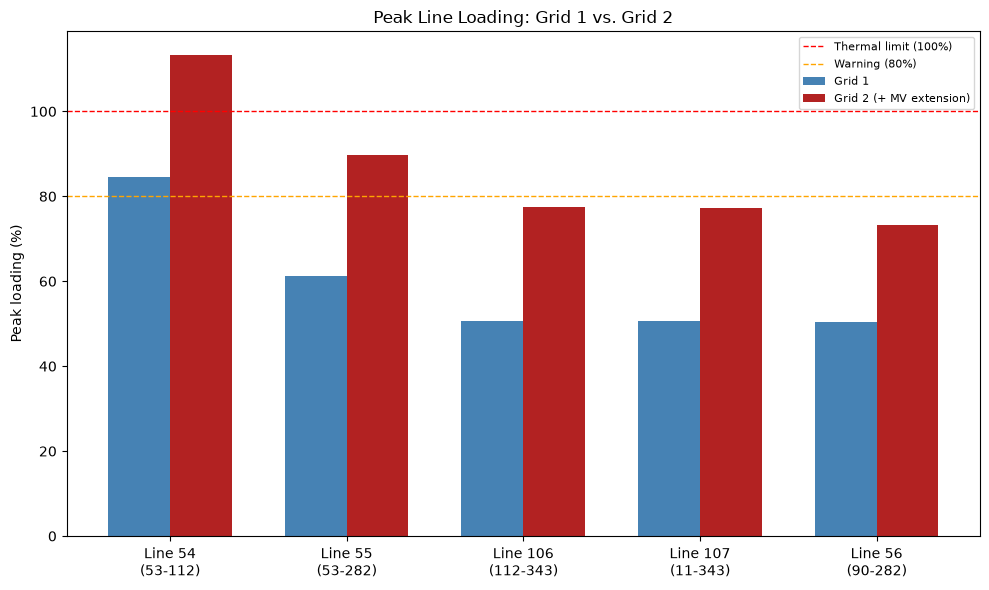

In [14]:
import numpy as np
import matplotlib.pyplot as plt

lines_common = ['Line 54\n(53-112)', 'Line 55\n(53-282)', 'Line 106\n(112-343)', 'Line 107\n(11-343)', 'Line 56\n(90-282)']
grid1_loading = [84.65, 61.22, 50.63, 50.60, 50.44]
grid2_loading = [113.20, 89.79, 77.40, 77.37, 73.15]

x = np.arange(len(lines_common))
width = 0.35
fig, ax = plt.subplots(figsize=(10, 6))
ax.bar(x - width/2, grid1_loading, width, label='Grid 1', color='steelblue')
ax.bar(x + width/2, grid2_loading, width, label='Grid 2 (+ MV extension)', color='firebrick')
ax.axhline(100, color='red', linestyle='--', linewidth=1, label='Thermal limit (100%)')
ax.axhline(80, color='orange', linestyle='--', linewidth=1, label='Warning (80%)')
ax.set_xticks(x); ax.set_xticklabels(lines_common)
ax.set_ylabel('Peak loading (%)')
ax.set_title('Peak Line Loading: Grid 1 vs. Grid 2')
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig('grid_comparison_lines.png', dpi=150)
plt.show()

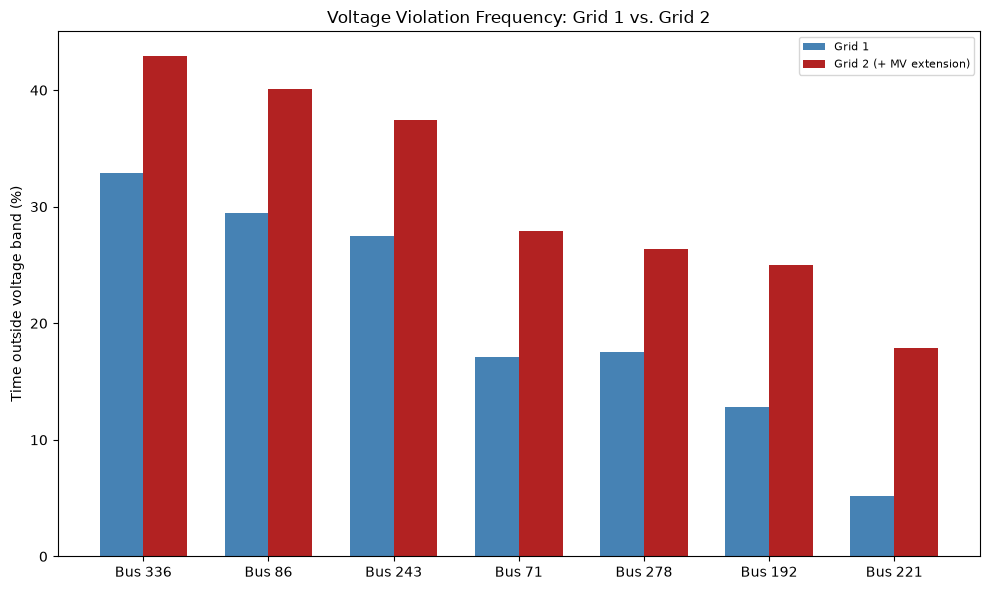

In [15]:
buses_common = ['Bus 336', 'Bus 86', 'Bus 243', 'Bus 71', 'Bus 278', 'Bus 192', 'Bus 221']
grid1_violation = [32.9, 29.5, 27.5, 17.1, 17.5, 12.8, 5.2]
grid2_violation = [42.9, 40.1, 37.4, 27.9, 26.4, 25.0, 17.9]

x = np.arange(len(buses_common))
fig, ax = plt.subplots(figsize=(10, 6))
ax.bar(x - width/2, grid1_violation, width, label='Grid 1', color='steelblue')
ax.bar(x + width/2, grid2_violation, width, label='Grid 2 (+ MV extension)', color='firebrick')
ax.set_xticks(x); ax.set_xticklabels(buses_common)
ax.set_ylabel('Time outside voltage band (%)')
ax.set_title('Voltage Violation Frequency: Grid 1 vs. Grid 2')
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig('grid_comparison_buses.png', dpi=150)
plt.show()